<a href="https://colab.research.google.com/github/Tanishqa298/ML_LAB_2026-27/blob/main/Multiple_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Multiple linear regression** is a statistical method that uses two or more independent variables to predict the value of a single dependent variable.

It is an extension of simple linear regression, and the model assesses how a dependent variable changes in response to changes in multiple independent variables.

The output is an equation that represents this relationship, and statistical measures like R-squared and p-values are used to evaluate the model's strength and the significance of the independent variables.  

--- Sample Data ---
   SquareFeet  Bedrooms  Bathrooms  Age   Price
0        1200         2        1.0   15  220000
1        1600         3        2.0    8  320000
2        2100         4        3.0    5  460000
3        1400         2        1.0   18  240000
4        2300         4        2.0    6  490000


--- Model Coefficients ---
Intercept: -116628.00067860179
Coefficients: [  149.42531173 58609.5088642  11295.48731869  1281.06709645]
             Coefficient
SquareFeet    149.425312
Bedrooms    58609.508864
Bathrooms   11295.487319
Age          1281.067096


--- Predictions vs Actual ---
   Actual Price  Predicted Price
5        350000    356096.467046
1        320000    331120.536093


--- Model Evaluation ---
Mean Absolute Error (MAE): 8608.50
Mean Squared Error (MSE): 80416616.72
Root Mean Squared Error (RMSE): 8967.53
R-squared (R²): 0.64




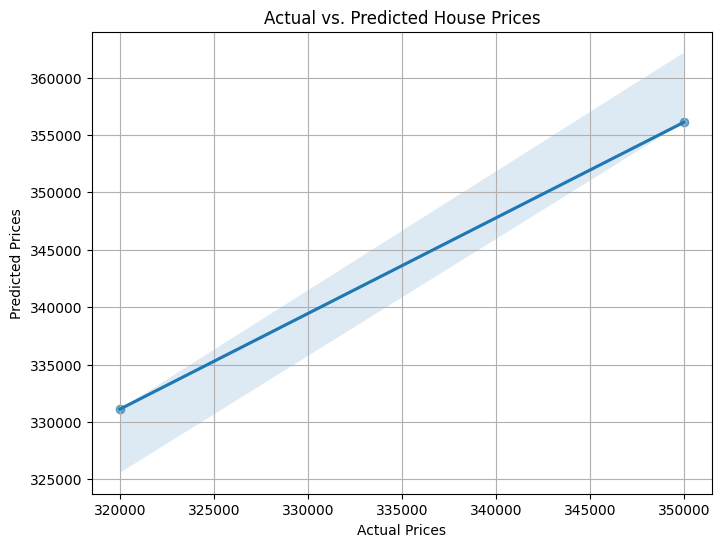

In [1]:

# Step 1: Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Create a sample dataset
data = {
    'SquareFeet': [1200, 1600, 2100, 1400, 2300, 1750, 2500, 1950, 2800, 1550],
    'Bedrooms': [2, 3, 4, 2, 4, 3, 5, 3, 5, 2],
    'Bathrooms': [1, 2, 3, 1, 2, 2, 3, 2.5, 4, 1.5],
    'Age': [15, 8, 5, 18, 6, 10, 3, 12, 4, 20],
    'Price': [220000, 320000, 460000, 240000, 490000, 350000, 590000, 400000, 650000, 270000]
}
df = pd.DataFrame(data)

# Display the first few rows of the dataframe
print("--- Sample Data ---")
print(df.head())
print("\n")

# Step 3: Define Features (X) and Target (y)
X = df[['SquareFeet', 'Bedrooms', 'Bathrooms', 'Age']]
y = df['Price']

# Step 4: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=25)

# Step 5: Create and Train the Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Print the model coefficients
print("--- Model Coefficients ---")
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

coeff_df = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])
print(coeff_df)
print("\n")

# Step 6: Make Predictions on the Test Set
y_pred = model.predict(X_test)

# Create a DataFrame to compare actual vs. predicted values
predictions_df = pd.DataFrame({'Actual Price': y_test, 'Predicted Price': y_pred})
print("--- Predictions vs Actual ---")
print(predictions_df)
print("\n")

# Step 7: Evaluate the Model's Performance
print('--- Model Evaluation ---')

# Mean Absolute Error (MAE)
mae = metrics.mean_absolute_error(y_test, y_pred)
print(f'Mean Absolute Error (MAE): {mae:.2f}')

# Mean Squared Error (MSE)
mse = metrics.mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error (MSE): {mse:.2f}')

# Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')

# R-squared (R²) Score
r2 = metrics.r2_score(y_test, y_pred)
print(f'R-squared (R²): {r2:.2f}')
print("\n")

# Optional: Visualize the results
plt.figure(figsize=(8, 6))
sns.regplot(x=y_test, y=y_pred, scatter_kws={'alpha':0.6})
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs. Predicted House Prices")
plt.grid(True)
plt.show()
